In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
import torch

In [3]:
df = pd.read_csv("08-seismic_activity_svm.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   underground_wave_energy   400 non-null    float64
 1   vibration_axis_variation  400 non-null    float64
 2   seismic_event_detected    400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB


In [5]:
df.head()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
0,9.539392,-3.000000,0
1,9.558241,-2.939394,0
2,9.576669,-2.878788,0
3,9.594678,-2.818182,0
4,9.612272,-2.757576,0


In [6]:
df["seismic_event_detected"].unique()

array([0, 1])

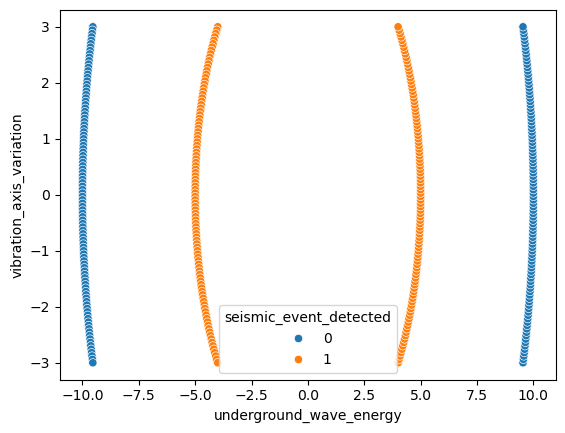

In [7]:
sns.scatterplot(x=df['underground_wave_energy'],y=df['vibration_axis_variation'],hue=df['seismic_event_detected'])
plt.show()

In [8]:
x = df[['underground_wave_energy','vibration_axis_variation']].values
y= df['seismic_event_detected'].values

In [9]:
x

array([[ 9.53939201, -3.        ],
       [ 9.55824059, -2.93939394],
       [ 9.57666854, -2.87878788],
       [ 9.59467828, -2.81818182],
       [ 9.61227215, -2.75757576],
       [ 9.62945245, -2.6969697 ],
       [ 9.64622137, -2.63636364],
       [ 9.66258107, -2.57575758],
       [ 9.67853361, -2.51515152],
       [ 9.69408101, -2.45454545],
       [ 9.70922521, -2.39393939],
       [ 9.7239681 , -2.33333333],
       [ 9.73831149, -2.27272727],
       [ 9.75225716, -2.21212121],
       [ 9.76580681, -2.15151515],
       [ 9.77896207, -2.09090909],
       [ 9.79172455, -2.03030303],
       [ 9.80409577, -1.96969697],
       [ 9.81607722, -1.90909091],
       [ 9.82767031, -1.84848485],
       [ 9.83887643, -1.78787879],
       [ 9.8496969 , -1.72727273],
       [ 9.86013297, -1.66666667],
       [ 9.87018588, -1.60606061],
       [ 9.87985679, -1.54545455],
       [ 9.88914683, -1.48484848],
       [ 9.89805706, -1.42424242],
       [ 9.90658851, -1.36363636],
       [ 9.91474216,

In [10]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
x_train , x_test , y_train ,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [13]:
x_train = torch.tensor(x_train,dtype=torch.float32)
y_train = torch.tensor(y_train,dtype=torch.float32)
x_test = torch.tensor(x_test,dtype=torch.float32)
y_test = torch.tensor(y_test,dtype=torch.float32)

In [14]:
x_train.shape

torch.Size([320, 2])

In [15]:
y_train.shape

torch.Size([320])

In [16]:
y_train = y_train.unsqueeze(1)
y_test = y_test.unsqueeze(1)

In [17]:
from torch import nn

In [18]:
class ClassificationModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(in_features=2,out_features=5)
        self.layer_2 = nn.Linear(in_features=5,out_features=5)
        self.layer_3 = nn.Linear(in_features=5,out_features=1)
        self.relu = nn.ReLU()
    def forward(self,x):
        x = self.relu(self.layer_1(x))
        x = self.relu(self.layer_2(x))
        x = self.layer_3(x)
        return x

In [19]:
model_0 = ClassificationModel()

In [20]:
loss_fn = nn.BCEWithLogitsLoss()

In [21]:
optimizer = torch.optim.Adam(params = model_0.parameters(),lr=0.01)

In [22]:
def calculate_accuracy(y_test,y_pred):
    correct = torch.eq(y_test,y_pred).sum().item()
    accuracy =(correct/len(y_pred))*100
    return accuracy

In [23]:
y_logits = model_0(x_test)[:10]

In [24]:
torch.sigmoid(y_logits)

tensor([[0.4377],
        [0.3614],
        [0.4797],
        [0.4375],
        [0.3944],
        [0.4078],
        [0.4250],
        [0.3929],
        [0.3822],
        [0.4705]], grad_fn=<SigmoidBackward0>)

In [25]:
y_pred = torch.round(y_logits)

In [26]:
calculate_accuracy(y_test[:5],y_pred[:5])

40.0

In [27]:
torch.manual_seed(42)
epochs = 400

for epoch in range(epochs):
    model_0.train()

    y_logits = model_0(x_train)
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits,y_train)
    acc = calculate_accuracy(y_train,y_pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model_0.eval()
    with torch.inference_mode():
        test_logits = model_0(x_test)
        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits,y_test)
        test_acc = calculate_accuracy(y_test,test_pred)

        if epoch%5==0:
            print(f"Epoch:{epoch},Loss:{loss},Accuracy:{acc},Test Loss:{test_loss},Test Accuracy:{test_acc}")   

Epoch:0,Loss:0.7616559267044067,Accuracy:35.625,Test Loss:0.7151226997375488,Test Accuracy:55.00000000000001
Epoch:5,Loss:0.7217020988464355,Accuracy:48.75,Test Loss:0.6667903065681458,Test Accuracy:55.00000000000001
Epoch:10,Loss:0.6928763389587402,Accuracy:48.75,Test Loss:0.644385039806366,Test Accuracy:55.00000000000001
Epoch:15,Loss:0.6656610369682312,Accuracy:48.75,Test Loss:0.6235671043395996,Test Accuracy:55.00000000000001
Epoch:20,Loss:0.6343628168106079,Accuracy:52.5,Test Loss:0.5896934866905212,Test Accuracy:58.75
Epoch:25,Loss:0.5938957333564758,Accuracy:55.93749999999999,Test Loss:0.54307621717453,Test Accuracy:63.74999999999999
Epoch:30,Loss:0.5477190017700195,Accuracy:59.68750000000001,Test Loss:0.49207383394241333,Test Accuracy:71.25
Epoch:35,Loss:0.4948483407497406,Accuracy:65.0,Test Loss:0.4334827959537506,Test Accuracy:77.5
Epoch:40,Loss:0.43604880571365356,Accuracy:80.0,Test Loss:0.37384214997291565,Test Accuracy:85.0
Epoch:45,Loss:0.37440699338912964,Accuracy:86.25,

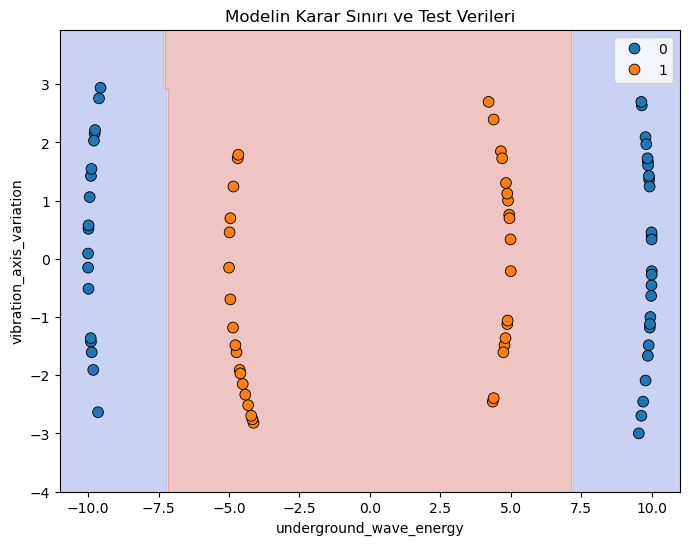

In [28]:
X_test_np = x_test.numpy()
y_test_np = y_test.squeeze().numpy()
# Izgara (grid) oluşturma
x_min, x_max = x_test[:, 0].min() - 1, x_test[:, 0].max() + 1
y_min, y_max = x_test[:, 1].min() - 1, x_test[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

# Izgaradaki tüm noktalar için modelden tahmin alma
grid_tensor = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
model_0.eval()
with torch.inference_mode():
    grid_preds = torch.round(torch.sigmoid(model_0(grid_tensor))).reshape(xx.shape)

# Grafiği çizdirme
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, grid_preds, alpha=0.3, cmap=plt.cm.coolwarm)
sns.scatterplot(
    x=X_test_np[:, 0], 
    y=X_test_np[:, 1], 
    hue=y_test_np.astype(int), 
    palette={0: "tab:blue", 1: "tab:orange"},
    edgecolor="k",
    s=60
)
plt.title("Modelin Karar Sınırı ve Test Verileri")
plt.xlabel("underground_wave_energy")
plt.ylabel("vibration_axis_variation")
plt.show()